### Cell 1

# 🇮🇳 Hindi → English Neural Machine Translation
### A beginner session: from "what is translation?" to a working Transformer

| | |
|---|---|
| **Audience** | Beginners; basic Python is enough, no prior Natural Language Processing (NLP) needed |
| **What gets built** | A small Transformer that translates Hindi to English, trained from scratch |
| **Runtime** | Graphics Processing Unit (GPU) recommended: Runtime → Change runtime type → T4 GPU |

### 📋 Session plan

| Part | Topic |
|---|---|
| 1 | Why Machine Translation (MT) matters, why Hindi is hard |
| 2 | Setup and the Samanantar data |
| 3 | Tokenization with Byte Pair Encoding (BPE) + Q1 |
| 4 | Batching and teacher forcing |
| 5 | The Transformer model |
| 6 | Training: loss, optimiser, epochs |
| 7 | Inference (greedy decoding) + Q2 |
| 8 | Pretrained MarianMT comparison and wrap-up |

### 🎬 Instructor runbook (read before class)

1. **Run everything once at the start:** Runtime → Run all. The data download, training and the MarianMT download then finish in the background while Parts 1 to 5 are being explained, so no class time is spent waiting.
2. Cells marked **⏭️ Optional** can be skipped without breaking anything that follows.
3. **Q1** and **Q2** are short "spot the bug" checkpoints. The answers are hidden in collapsible boxes.
4. Each markdown cell ends with a **💬 Say** line (what to tell the class) and **✅ Takeaways**.

### 🗺️ The story of the session

```
Why translation matters → the data → text to numbers → a Transformer from scratch
      → train it → it translates badly → understand WHY → a pretrained model fixes it
```

> 🪝 **Hook question for the class:** can a small model trained on only 5,000 sentences compete with Google Translate? Keep the answer for the end.

### Cell 2

---
## Part 1 · Why does MT matter?

India has **22 scheduled languages** and hundreds of dialects, while a large share of web content is in English. MT closes this information gap:

| Situation | Without MT | With MT |
|-----------|-----------|---------|
| Farmer reads a government crop advisory | Only if printed in their language | Instantly in their own language |
| Student reads Wikipedia | Only English/Hindi articles | Millions of articles in any language |
| Doctor reads World Health Organization (WHO) guidelines | English-only access | Real-time translation |
| Small business exports goods | Expensive human translator | Automated invoice/contract translation |

Where it ships today: health bulletins, court judgements (eCourts), news syndication, e-commerce listings, and lecture subtitling (e.g. NPTEL).

### How MT evolved

```
1950s  Rule-based MT       → hand-written grammar rules, brittle
1990s  Statistical MT      → phrase tables learned from data, still rigid
2014   Neural MT (RNN)     → sequence-to-sequence with attention
2017   Transformer         → "Attention Is All You Need", today's standard
2022+  Samanantar / IndicTrans2 → Transformers at Indian-language scale
```

The **Transformer** (built in this session) powers Google Translate, DeepL, Meta's NLLB-200 and AI4Bharat's IndicTrans2.

### Why is Hindi → English harder than French → English?

| Feature | French → English | Hindi → English |
|---------|---------------|---------------|
| Word order | Subject-Verb-Object (SVO) → SVO | Subject-Object-Verb (SOV) → SVO |
| Script | Latin → Latin | Devanagari → Latin |
| Morphology | Low | High (gender × number × tense) |
| Parallel data | Very large | Much smaller |

```text
French:  Je mange une pomme.        →  I eat an apple.        (same order)
Hindi:   मैं एक सेब खाता हूँ।            →  literally "I an apple eat"
English: I eat an apple.                (the model must learn to REORDER)
```

**💬 Say:** "Translation is not word substitution. For Hindi, the model must learn meanings *and* reordering."

**✅ Takeaways**
- MT is a sequence-to-sequence problem with large real-world value.
- Hindi → English adds word reordering, a script change and rich morphology.

### Cell 3

---
## Part 2 · Setup and data: Samanantar 📚

To learn translation, a model studies **parallel sentence pairs**: the same sentence in Hindi and in English.

**Samanantar** (Sanskrit for *"parallel"*) is a free corpus released by **AI4Bharat (IIT Madras)** in 2022 (published in TACL):

| Fact | Value |
|------|-------|
| Total size | ~49.6M English ↔ Indic sentence pairs across 11 languages |
| English-Hindi | ~8.6M pairs (v0.2 release) |
| Sources | Existing public corpora + sentences mined from the web |
| Licence | Free and open |

**Analogy:** a bilingual book with Hindi on the left page and English on the right, millions of pages long.

**Today:** only **5,000 pairs** are streamed so that training stays quick. This choice is deliberate and becomes the key lesson at the end.

Tools used: **PyTorch** (neural network), **SentencePiece** (subword tokenizer), **Hugging Face `datasets`** (data access), **`transformers`** (pretrained model at the end).

**💬 Say:** "Each training example is a pair. The model never sees grammar rules, only pairs."

In [ ]:
# Cell 4 | Setup: install packages, import, choose device, fix random seeds

# Install the extra libraries quietly (-q hides the long install log):
#   sentencepiece   -> trains the BPE subword tokenizers
#   datasets        -> downloads/streams the Samanantar corpus from Hugging Face
#   deep-translator -> calls Google Translate for the optional benchmark cell
#   transformers    -> loads the pretrained MarianMT model at the end
!pip install -q sentencepiece datasets deep-translator transformers

import math, os, random, time
# math: sqrt/log for the model; os: create folders; random: shuffling; time: measure training time
import torch
# PyTorch: tensors, GPU support and automatic gradients
import torch.nn as nn
# Neural-network building blocks (Embedding, Transformer, Linear, loss functions)
import torch.optim as optim
# Optimisers that update the weights (we use Adam)
from torch.utils.data import Dataset, DataLoader
# Dataset stores examples; DataLoader groups them into shuffled mini-batches
import sentencepiece as spm
# SentencePiece library, used to train and apply the BPE tokenizers

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Use the GPU ("cuda") if one is available, otherwise fall back to the CPU
print(f"PyTorch {torch.__version__} | device: {device}")
# Show the PyTorch version and which device was selected
if device.type == "cuda":
# If a GPU was found ...
    print(f"GPU: {torch.cuda.get_device_name(0)}")
# ... print its name (on Colab this is usually "Tesla T4")
else:
# Otherwise no GPU is attached ...
    print("Tip: Runtime → Change runtime type → T4 GPU (CPU training is much slower)")
# ... so remind the user how to enable one

random.seed(42)
# Fix Python's random seed so the train/validation shuffle is the same on every run
torch.manual_seed(42)
# Fix PyTorch's random seed so the model starts from the same random weights on every run
print("Ready!")
# Confirm that setup finished without errors

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.3/42.3 kB 3.4 MB/s eta 0:00:00
PyTorch 2.11.0+cu130 | device: cuda
GPU: Tesla T4
Ready!


### 📤 Understanding the output of Cell 4

| Output line | What it means |
|---|---|
| `━━━━━━━━ 42.3/42.3 kB 3.7 MB/s eta 0:00:00` | `pip` downloaded one small package (42.3 kB, most likely `deep-translator`). The full bar and `eta 0:00:00` show the download **completed**. The other packages (`sentencepiece`, `datasets`, `transformers`) were already installed in Colab, so nothing was printed for them because of the `-q` (quiet) flag. |
| `PyTorch 2.11.0+cu130` | The installed PyTorch version is **2.11.0**. The suffix `+cu130` means this build supports **CUDA 13.0**, NVIDIA's GPU computing platform, so PyTorch can run on the GPU. |
| `device: cuda` | A GPU was detected, so all tensors and the model will be placed on the **GPU** (`cuda`) instead of the CPU. |
| `GPU: Tesla T4` | The GPU is an **NVIDIA Tesla T4** (16 GB memory), the free GPU offered by Colab, which is enough to train our small Transformer quickly. |
| `Ready!` | All imports succeeded and the random seeds were fixed. The notebook is ready for the next step: **loading the data**. |

**✅ Takeaway:** The environment is set up correctly and the GPU is active. If the output had said `device: cpu`, enable the GPU via **Runtime → Change runtime type → T4 GPU** and run this cell again.

In [ ]:
# Cell 5 | Stream 5,000 Hindi-English pairs from Samanantar
from datasets import load_dataset
# Hugging Face function that downloads/streams public datasets

print("Loading 5,000 sentence pairs from ai4bharat/samanantar ...")
# Tell the user the download has started
ds = load_dataset("ai4bharat/samanantar",         # Dataset name on the Hugging Face Hub (published by AI4Bharat)
                  "hi",                           # Configuration: the English-Hindi part of Samanantar
                  split="train",                  # Use the training split (the only split provided)
                  streaming=True)                 # Stream rows one by one instead of downloading all ~8.6M pairs

PAIRS = []                                        # Empty list that will hold (Hindi, English) tuples
for row in ds:                                    # Read one sentence pair (row) at a time from the stream
    hi = row["tgt"].strip()                       # 'tgt' column holds the Hindi sentence; strip() removes extra spaces/newlines
    en = row["src"].strip()                       # 'src' column holds the English sentence; strip() cleans it the same way
    if hi and en:                                 # Keep the pair only if neither side is empty
        PAIRS.append((hi, en))                    # Store the cleaned pair as a tuple (Hindi first, English second)
    if len(PAIRS) >= 5000:                        # Once 5,000 pairs are collected ...
        break                                     # ... stop reading, so no more data is downloaded

print(f"Loaded {len(PAIRS)} sentence pairs\n")        # Confirm how many pairs were collected (should be 5000)
print("Examples from the dataset:")                   # Heading for the sample printout
print("-" * 55)                                       # Print a line of 55 dashes as a visual separator
for hi, en in PAIRS[:4]:                              # Loop over the first 4 pairs, unpacking each into hi and en
    print(f"  Hindi  : {hi}")                         # Show the Hindi sentence
    print(f"  English: {en}\n")                       # Show its English translation, followed by a blank line

# ✅ Check: the Hindi and English lines really are translations of each other.
#    Note the 4th example (Mithali); it is reused in the next cell.

Loading 5,000 sentence pairs from ai4bharat/samanantar ...


README.md:   0%|          | 0.00/11.4k [00:00<?, ?B/s]

Loaded 5000 sentence pairs

Examples from the dataset:
-------------------------------------------------------
  Hindi  : आस्ट्रेलिया के पाल हेनली के साथ जोड़ी बनाने वाले पेस मियामी में क्वार्टरफाइनल तक ही पहुंच सके क्योंकि इस दौर में उन्हें भूपति और नोल्स ने हराया था।
  English: However, Paes, who was partnering Australia's Paul Hanley, could only go as far as the quarterfinals where they lost to Bhupathi and Knowles

  Hindi  : और जो शख्स (अपने आमाल का) बदला दुनिया ही में चाहता है तो ख़ुदा के पास दुनिया व आख़िरत दोनों का अज्र मौजूद है और ख़ुदा तो हर शख्स की सुनता और सबको देखता है
  English: Whosoever desires the reward of the world, with Allah is the reward of the world and of the Everlasting Life. Allah is the Hearer, the Seer.

  Hindi  : जैव-मंडल में कीड़ों का मूल्य बहुत है, क्योंकि प्रजातियों की समृद्धि के मामले में उनकी संख्या अन्य जीव समूहों से ज़्यादा है।
  English: The value of insects in the biosphere is enormous because they outnumber all other living groups in measure of sp

### 📤 Understanding the output of Cell 5

| Output | What it means |
|---|---|
| `Loading 5,000 sentence pairs ...` | The streaming download has started. |
| `README.md: 100% 11.4k/11.4k` | Only the dataset's description file (11.4 kB) was downloaded up front. Because of `streaming=True`, sentence pairs are fetched as they are read, so the full corpus (millions of pairs) is **never downloaded**. |
| `Loaded 5000 sentence pairs` | The loop collected exactly 5,000 non-empty Hindi-English pairs and stopped. |
| The 4 examples | Each Hindi sentence is followed by its English translation, confirming that `tgt` = Hindi and `src` = English. |

**What the examples reveal about real-world data**
- **Mixed domains:** sports news, a religious text, a science sentence and a newspaper headline. The model must handle very different vocabulary and styles.
- **Translations are not word-for-word:** the English in example 1 begins with *"However"*, which has no matching Hindi word, and example 4 is a short headline rendered loosely (*"कमान"* "command" → *"Anchor"*).
- **Word order differs:** Hindi places the verb at the end (*"... हराया था"*), English places it in the middle. The model has to learn this reordering.
- **Example 4 (Mithali)** is reused in the next cell to compare against Google Translate.

**✅ Takeaway:** The data loaded correctly. It is real, noisy, multi-domain text, which makes learning from only 5,000 pairs genuinely hard.

### Cell 6

### ⏭️ Optional · The benchmark: what does Google Translate produce?

Before building a model, a mature production system is used as a reference point. The sentence below is the 4th example printed above.

**💬 Say:** "This is the bar. Remember this output when the scratch model's translations appear."

In [ ]:
# Cell 7 | ⏭️ Optional: reference translation from Google Translate (needs internet)

import importlib.util, subprocess, sys, time
# importlib.util: checks whether a package is installed
# subprocess, sys: run pip from inside Python using the current interpreter
# time: pause between retry attempts

if importlib.util.find_spec("deep_translator") is None:
    # Check whether deep-translator is missing from the current session
    # (packages are lost whenever the Colab runtime restarts)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "deep-translator"], check=True)
    # Install it quietly (-q); check=True raises an error if installation fails

from deep_translator import GoogleTranslator
# Import the wrapper class that sends text to Google Translate

text = "आस्ट्रेलिया के खिलाफ वनडे टीम की कमान मिताली को"
# Hindi sentence to translate: the 4th example from the dataset (Mithali headline)

SAVED = "Mithali to command ODI team against Australia"
# Google's output from an earlier successful run, used as a fallback

google_out = None
# Placeholder for the live translation; stays None if every request fails

for attempt in range(3):
    # Try the request up to 3 times (attempt = 0, 1, 2)

    try:
        # Attempt the code below; jump to "except" if an error occurs

        google_out = GoogleTranslator(source="hi", target="en").translate(text)
        # Send the Hindi text to Google Translate and store the English result

        break
        # The request succeeded, so exit the retry loop immediately

    except Exception as e:
        # Catch any error, e.g. TooManyRequests (rate limit) or a network failure

        wait = 2 * (attempt + 1)
        # Waiting time grows with each attempt: 2 s after the first, 4 s after the second

        print(f"Attempt {attempt + 1} failed ({type(e).__name__})"
              + (f", retrying in {wait} s ..." if attempt < 2 else ""))
        # Report which attempt failed and the error type;
        # mention the retry only if another attempt remains

        if attempt < 2:
            # Only wait if there is still an attempt left

            time.sleep(wait)
            # Pause before retrying, giving Google's rate limit time to reset

if google_out is None:
    # True only if all 3 attempts failed

    google_out = SAVED + "   (saved result: live request was rate-limited)"
    # Use the saved translation and label it clearly, so "Run all" continues

print("Google   :", google_out)
# Display Google Translate's output (live or saved)

print("Reference: Mithali To Anchor Indian Team Against Australia in ODIs")
# Display the human reference translation from Samanantar for comparison

Attempt 1 failed (TooManyRequests), retrying in 2 s ...
Attempt 2 failed (TooManyRequests), retrying in 4 s ...
Attempt 3 failed (TooManyRequests)
Google   : Mithali to command ODI team against Australia   (saved result: live request was rate-limited)
Reference: Mithali To Anchor Indian Team Against Australia in ODIs


### 📤 Understanding the output of Cell 7

| Output line | What it means |
|---|---|
| `Attempt 1 failed (TooManyRequests), retrying in 2 s ...` | Google refused the first request with a **rate-limit error (HTTP 429)**. The cell waited 2 seconds before trying again. |
| `Attempt 2 failed (TooManyRequests), retrying in 4 s ...` | The second request was also refused, so the cell waited longer (4 seconds). |
| `Attempt 3 failed (TooManyRequests)` | The final attempt failed too. No further retry is made. |
| `Google : Mithali to command ODI team against Australia (saved result: ...)` | Because all live requests failed, the cell displayed the **translation saved from an earlier successful run**, clearly labelled as saved. |
| `Reference: Mithali To Anchor Indian Team Against Australia in ODIs` | The human translation from the Samanantar dataset, shown for comparison. |

**Why the requests failed:** Colab machines share IP addresses with many users. Google sees a large number of requests from the same address and temporarily blocks it. This is **not a bug in the code**, and the fallback ensured the notebook kept running.

**Comparing the two translations**
- Google's output keeps the **meaning** correctly (Mithali leads the One Day International (ODI) team against Australia).
- It differs in **wording** from the reference (*"command"* vs *"Anchor"*, *"ODI team"* vs *"Team ... in ODIs"*). Both are valid: a sentence usually has several correct translations.

**✅ Takeaway:** This is the quality benchmark. Keep it in mind when the scratch model's translations appear later.

**💡 Tip:** To get a live result, use **Runtime → Disconnect and delete runtime** and reconnect. This usually assigns a new machine with a different IP address.

### Cell 8

---
## Part 3 · Tokenization: text → numbers

A neural network only reads numbers, so every sentence becomes a list of integer IDs.

**Why not one ID per word?** Hindi has a huge number of word forms (खेल, खेलता, खेलती, खेलते, खेलना ...). A word-level vocabulary would be enormous and would still meet unseen words.

**BPE** learns **subword pieces** instead:

1. Start with single characters as the vocabulary.
2. Repeatedly find the most frequent adjacent pair and merge it into a new piece.
3. Stop when the vocabulary reaches the chosen size (here **4,000** per language).

```
खेलता  →  [ खेल + ता ]        (like "playing" → "play" + "ing")
```

Unseen words can still be built from known pieces, so very few tokens become unknown.

**Key settings in the next cell**
- **Separate tokenizers for Hindi and English:** different scripts, different vocabularies. ID 42 means different pieces in each.
- **Special IDs:** `<pad>`=0 (filler for equal length), `<s>`=1 (beginning of sentence), `</s>`=2 (end of sentence), `<unk>`=3 (unknown).
- **`character_coverage`:** fraction of characters kept as-is. Devanagari has many more distinct characters than Latin, so Hindi uses 0.9999 and English 0.9995.

**💬 Say:** "The `▁` symbol in the output marks the start of a word."

In [ ]:
# Cell 9 | Safety check before training the tokenizers (loads the data if it is missing)

import importlib.util, subprocess, sys
# Tools to check whether a package is installed and install it if needed

for pkg in ["sentencepiece", "datasets"]:
    # Loop over the two packages this part of the notebook needs

    if importlib.util.find_spec(pkg) is None:
        # True if the package is missing (packages are lost when the Colab runtime restarts)

        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
        # Install it quietly; check=True raises an error if installation fails

import os
# Standard library module for folders and files (used to create the "spm" folder)

import sentencepiece as spm
# SentencePiece library, used to train and load the BPE tokenizers

if "PAIRS" not in globals() or len(PAIRS) == 0:
    # True if the sentence pairs from Cell 5 do not exist in this session

    from datasets import load_dataset
    # Hugging Face function that streams public datasets

    print("PAIRS not found: loading 5,000 sentence pairs from Samanantar ...")
    # Tell the user why there is a short wait

    PAIRS = []
    # Empty list that will hold (Hindi, English) tuples

    for row in load_dataset("ai4bharat/samanantar", "hi", split="train", streaming=True):
        # Stream the English-Hindi part of Samanantar one row at a time

        hi, en = row["tgt"].strip(), row["src"].strip()
        # 'tgt' column is Hindi, 'src' column is English; strip() removes extra spaces

        if hi and en:
            # Check that neither sentence is empty

            PAIRS.append((hi, en))
            # Store the cleaned pair as a tuple (Hindi first, English second)

        if len(PAIRS) >= 5000:
            # Check whether 5,000 pairs have been collected

            break
            # Stop reading, so no more data is downloaded

print(f"✅ Libraries loaded and {len(PAIRS):,} sentence pairs found. Ready to train the tokenizers.")
# Confirm that everything needed for the next cell is in place

PAIRS not found: loading 5,000 sentence pairs from Samanantar ...


README.md:   0%|          | 0.00/11.4k [00:00<?, ?B/s]

✅ Libraries loaded and 5,000 sentence pairs found. Ready to train the tokenizers.


### 📤 Understanding the output of Cell 9

| Part of the output | What it means |
|---|---|
| `Libraries loaded` | `os` and `sentencepiece` were imported without errors, so the tools for creating folders and training tokenizers are available. |
| `5,000 sentence pairs found` | The `PAIRS` list created in Cell 5 exists in this session and contains all **5,000 Hindi-English pairs**. Nothing was lost to a runtime restart. |
| `Ready to train the tokenizers` | Every requirement for the next cell is in place, so Cell 9 can safely train the Hindi and English tokenizers. |

**Why this check matters:** Colab clears all variables and imports whenever the runtime restarts. Without this check, a missing `PAIRS` or `os` would cause a confusing `NameError` in Cell 9. With it, any problem is reported clearly before tokenizer training starts.

**✅ Takeaway:** The environment and data are confirmed. Proceed to Cell 9.

### Cell 10

### ❓ Q1 · Spot the bug

A student wrote this line to train the Hindi tokenizer. Nothing crashes at first sight, but translation quality would collapse. **What is wrong?**

```python
train_tokenizer(hi_sentences, "spm/hindi", vocab_size=30, lang="en")
```

<details>
<summary><b>👉 Click for the answer</b></summary>

- **`vocab_size=30` should be `4000`.** Thirty pieces cannot even hold the basic Devanagari character set, so SentencePiece either refuses to train or almost everything becomes `<unk>`.
- **`lang="en"` should be `lang="hi"`.** With `"en"` the function picks `character_coverage=0.9995`, so rare Devanagari characters are silently mapped to `<unk>`.

Correct line: `train_tokenizer(hi_sentences, "spm/hindi", vocab_size=4000, lang="hi")`
</details>

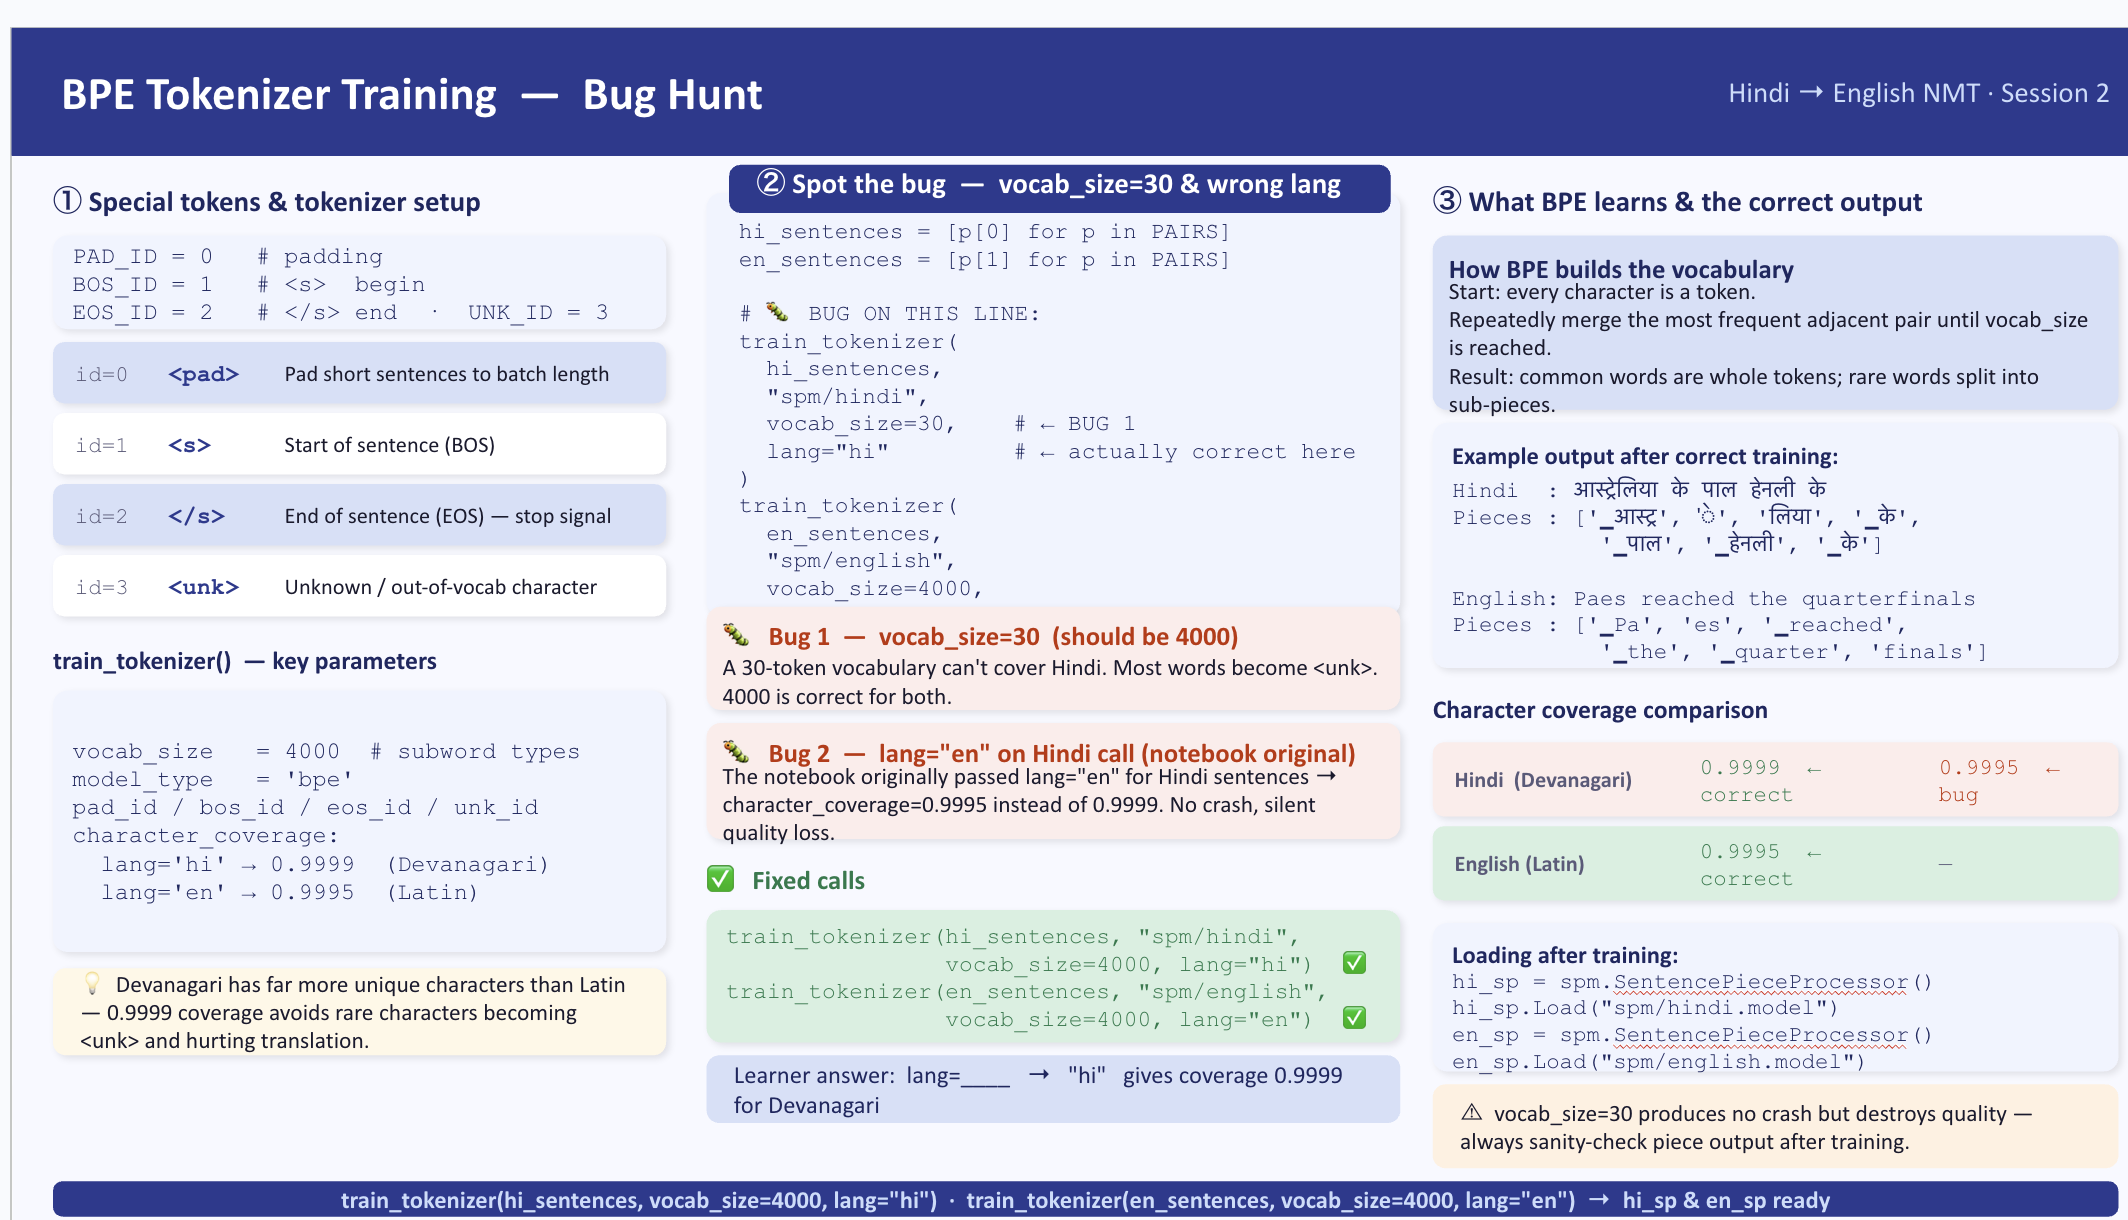

**✅ Takeaways**
- Token IDs are vocabulary-specific addresses, not universal meanings.
- Character coverage is a preprocessing setting, not a translation-accuracy score.

### Cell 11

---
## Part 4 · Batching and teacher forcing

### 4.1 From sentence pairs to padded mini-batches

```
PAIRS (raw text) → encode() → TranslationDataset → collate() pads → DataLoader → model
```

- **`encode`** adds `<s>` at the start and `</s>` at the end, then clips to 100 tokens.
- **Padding:** sentences in a batch have different lengths, so shorter ones are filled with `<pad>`=0 to form a rectangular tensor. The model is later told to **ignore** these positions.
- **Split:** 90% training (the model learns from it), 10% validation (never trained on; it measures generalisation).

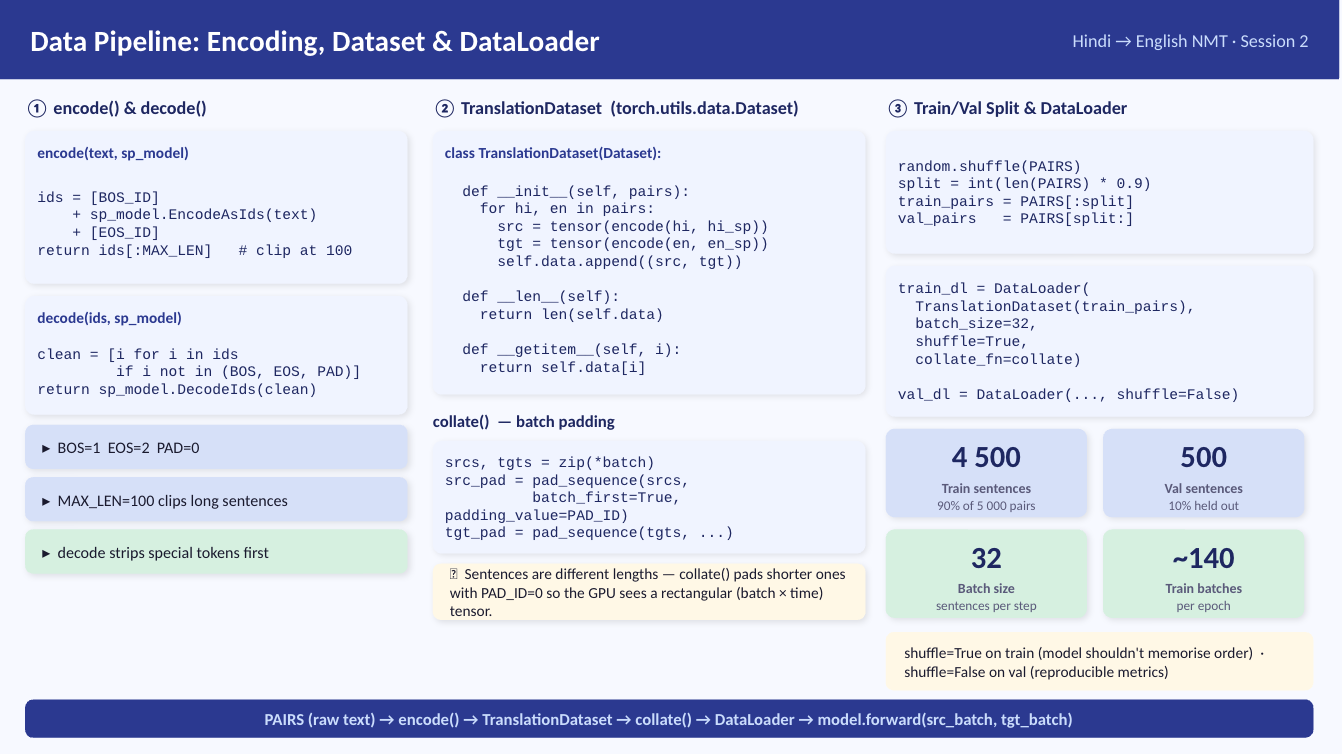

In [ ]:
# Cell 12A | Safety net: make sure the data and tokenizers exist (rebuilds them if lost)

import importlib.util, subprocess, sys
# importlib.util: checks whether a package is installed
# subprocess, sys: run pip from inside Python using the current interpreter

for pkg, module in [("sentencepiece", "sentencepiece"), ("datasets", "datasets")]:
    # Loop over each required package: pkg = name for pip, module = name used in import

    if importlib.util.find_spec(module) is None:
        # True if the package is not installed in this session (e.g. after a runtime restart)

        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
        # Install the missing package quietly; check=True raises an error if installation fails

import os
# os: check for saved tokenizer files and create folders

import sentencepiece as spm
# SentencePiece library, used to train or load the BPE tokenizers

PAD_ID, BOS_ID, EOS_ID = 0, 1, 2
# Special token IDs: <pad> = 0, <s> = 1, </s> = 2 (same values as the tokenizer cell)

# Step A: make sure the 5,000 sentence pairs exist
if "PAIRS" not in globals() or len(PAIRS) == 0:
    # True if PAIRS does not exist in this session or is empty (Cell 5 was not run)

    from datasets import load_dataset
    # Hugging Face function that downloads/streams public datasets

    print("PAIRS not found: streaming 5,000 pairs from Samanantar ...")
    # Tell the user why there is a short wait

    PAIRS = []
    # Empty list that will hold (Hindi, English) tuples

    for row in load_dataset("ai4bharat/samanantar", "hi", split="train", streaming=True):
        # Stream the English-Hindi part of Samanantar one row at a time

        hi, en = row["tgt"].strip(), row["src"].strip()
        # 'tgt' column is Hindi, 'src' column is English; strip() removes extra spaces

        if hi and en:
            # Check that neither sentence is empty

            PAIRS.append((hi, en))
            # Store the cleaned pair as a tuple (Hindi first, English second)

        if len(PAIRS) >= 5000:
            # Check whether 5,000 pairs have been collected

            break
            # Stop reading, so no more data is downloaded

# Step B: make sure both tokenizers exist
if "hi_sp" not in globals() or "en_sp" not in globals():
    # True if either tokenizer is missing from this session (tokenizer cell was not run)

    if not (os.path.exists("spm/hindi.model") and os.path.exists("spm/english.model")):
        # True if the saved tokenizer files are also missing from disk

        print("Tokenizers not found: training them now ...")
        # Tell the user that tokenizers are being trained

        os.makedirs("spm", exist_ok=True)
        # Create the "spm" folder; exist_ok=True avoids an error if it already exists

        for texts, name, lang in [([p[0] for p in PAIRS], "spm/hindi", "hi"),
                                  ([p[1] for p in PAIRS], "spm/english", "en")]:
            # Two passes: first the Hindi sentences, then the English sentences

            spm.SentencePieceTrainer.Train(
                sentence_iterator=iter(texts), model_prefix=name, vocab_size=4000,
                character_coverage=0.9999 if lang == "hi" else 0.9995, model_type="bpe",
                pad_id=PAD_ID, bos_id=BOS_ID, eos_id=EOS_ID, unk_id=3,
                pad_piece="<pad>", bos_piece="<s>", eos_piece="</s>", unk_piece="<unk>")
            # Train a 4,000-piece BPE tokenizer with the same settings as the tokenizer cell

    hi_sp = spm.SentencePieceProcessor(model_file="spm/hindi.model")
    # Load the Hindi tokenizer from disk

    en_sp = spm.SentencePieceProcessor(model_file="spm/english.model")
    # Load the English tokenizer from disk

print(f"✅ {len(PAIRS):,} sentence pairs and both tokenizers are ready.")
# Confirm that everything needed for Cell 12B is in place

Tokenizers not found: training them now ...
✅ 5,000 sentence pairs and both tokenizers are ready.


### 📤 Understanding the output of Cell 12A

| Part of the output | What it means |
|---|---|
| `5,000 sentence pairs` | The `PAIRS` list contains all **5,000 Hindi-English pairs** needed to build the training and validation sets. |
| `both tokenizers are ready` | The Hindi tokenizer (`hi_sp`) and the English tokenizer (`en_sp`) are loaded, so sentences can be converted into token IDs in the next cell. |

**What did *not* appear is also informative**
- No `PAIRS not found ...` message → the data from **Cell 5** was already in memory, so nothing was downloaded again.
- No `Tokenizers not found ...` message → the tokenizers already existed (in memory or as saved files in the `spm/` folder), so nothing was retrained.

So this cell only **checked** that everything was in place. It rebuilds the data or tokenizers only when they are missing, for example after a runtime restart.

**✅ Takeaway:** All prerequisites for the data pipeline are confirmed. Proceed to Cell 12B.

In [ ]:
# Cell 12B | Data pipeline: encode → Dataset → pad in collate → DataLoader

import random
# random: reproducible shuffling of the sentence pairs

import torch
# PyTorch: provides torch.tensor for storing token IDs

import torch.nn as nn
# Neural-network utilities; nn.utils.rnn.pad_sequence is used for padding

from torch.utils.data import Dataset, DataLoader
# Dataset: base class for TranslationDataset; DataLoader: groups examples into mini-batches

MAX_LEN = 100
# Maximum number of tokens allowed per sentence; longer sentences are cut off

def encode(text, sp_model, max_len=MAX_LEN):
    # Convert one sentence into a list of token IDs

    return ([BOS_ID] + sp_model.EncodeAsIds(text) + [EOS_ID])[:max_len]
    # Add <s> at the start and </s> at the end, then keep at most max_len IDs

def decode(ids, sp_model):
    # Convert a list of token IDs back into text

    return sp_model.DecodeIds([i for i in ids if i not in (BOS_ID, EOS_ID, PAD_ID)])
    # Remove <s>, </s> and <pad>, then let the tokenizer join the pieces into text

class TranslationDataset(Dataset):
    # A PyTorch Dataset that stores all sentence pairs as tensors of token IDs

    def __init__(self, pairs):
        # Runs once when the dataset is created from a list of (Hindi, English) pairs

        self.data = [(torch.tensor(encode(hi, hi_sp), dtype=torch.long),
                      torch.tensor(encode(en, en_sp), dtype=torch.long))
                     for hi, en in pairs]
        # Encode Hindi with hi_sp and English with en_sp; store both as integer tensors

    def __len__(self):
        # Method PyTorch calls to ask how many examples the dataset has

        return len(self.data)
        # Return the number of sentence pairs

    def __getitem__(self, i):
        # Method PyTorch calls to fetch one example by its index i

        return self.data[i]
        # Return the i-th (Hindi tensor, English tensor) pair

def collate(batch):
    # Combine several pairs of different lengths into one rectangular batch

    srcs, tgts = zip(*batch)
    # Separate the batch into all Hindi tensors (srcs) and all English tensors (tgts)

    pad = lambda seqs: nn.utils.rnn.pad_sequence(seqs, batch_first=True, padding_value=PAD_ID)
    # Fill shorter sequences with <pad> (0); batch_first=True gives shape (batch, length)

    return pad(srcs), pad(tgts)
    # Return the padded Hindi batch and the padded English batch

shuffled = list(PAIRS)
# Make a copy of PAIRS, so the original list is never modified

random.Random(42).shuffle(shuffled)
# Shuffle the copy with a fixed seed: the split is identical every time this cell is re-run

split = int(len(shuffled) * 0.9)
# Index at 90% of the data: 5000 × 0.9 = 4500

train_pairs, val_pairs = shuffled[:split], shuffled[split:]
# First 4,500 pairs for training, remaining 500 for validation

train_dl = DataLoader(TranslationDataset(train_pairs), batch_size=32, shuffle=True, collate_fn=collate)
# Training loader: 32 pairs per batch, reshuffled every epoch, padded by collate

val_dl = DataLoader(TranslationDataset(val_pairs), batch_size=32, shuffle=False, collate_fn=collate)
# Validation loader: same batch size, fixed order so results are comparable across epochs

src_b, tgt_b = next(iter(train_dl))
# Take one batch from the training loader as a final self-test of the pipeline

print(f"Training sentences  : {len(train_pairs)}")
# Show the number of training pairs (4500)

print(f"Validation sentences: {len(val_pairs)}")
# Show the number of validation pairs (500)

print(f"Train batches: {len(train_dl)}")
# Show batches per epoch: 4500 / 32 = 140.6, rounded up to 141

print(f"Sample batch shapes : Hindi {tuple(src_b.shape)}, English {tuple(tgt_b.shape)}")
# Show the batch shape (32, longest sentence in this batch); confirms padding worked

Training sentences  : 4500
Validation sentences: 500
Train batches: 141
Sample batch shapes : Hindi (32, 100), English (32, 100)


### 📤 Understanding the output of Cell 12B

| Output line | What it means |
|---|---|
| `Training sentences : 4500` | **90%** of the 5,000 pairs are used for training. The model learns from these. |
| `Validation sentences : 500` | The remaining **10%** are held out. The model never trains on them; they measure how well it handles **unseen** sentences. |
| `Train batches : 141` | 4,500 ÷ 32 = 140.6, rounded up to **141 batches per epoch**: 140 full batches of 32 and one final batch of 20 (140 × 32 + 20 = 4,500). |
| `Hindi (32, 55)` | One training batch holds **32 Hindi sentences**, each padded to **55 tokens**, the length of the longest Hindi sentence in this batch (including `<s>` and `</s>`). Shorter sentences are filled with `<pad>` (ID 0). |
| `English (32, 55)` | The matching **32 English translations**, padded to the longest English sentence in the same batch, which also happens to be 55 tokens. |

**Points worth noting**
- **Equal lengths are a coincidence.** Hindi and English are padded **separately**, so the two numbers usually differ. They also change from batch to batch, because each batch is padded only to its own longest sentence. This is more efficient than padding everything to `MAX_LEN = 100`.
- **The shape format is (batch size, sequence length)**, thanks to `batch_first=True`. This is exactly the shape the Transformer expects.
- **Padding makes the batch rectangular**, which the GPU needs. Later, the model and the loss function are told to **ignore** the `<pad>` positions.

**✅ Takeaway:** The data pipeline works. Text has become padded tensors of token IDs, split into training and validation sets and grouped into batches, ready for the model.

### Cell 13

### 4.2 Teacher forcing: how the decoder is trained

The decoder learns to **predict the next English token**. During training it is given the *correct* previous tokens (not its own guesses), which makes learning fast and stable:

```
full target : [<s>,  w1,  w2,  w3, </s>]
decoder IN  : [<s>,  w1,  w2,  w3]        ← tgt[:, :-1]  (drop last)
must PREDICT: [ w1,  w2,  w3, </s>]       ← tgt[:,  1:]  (drop first)
```

Position *t* sees tokens up to *t* and must output token *t+1*. A **causal mask** (Part 5) stops it from peeking ahead.

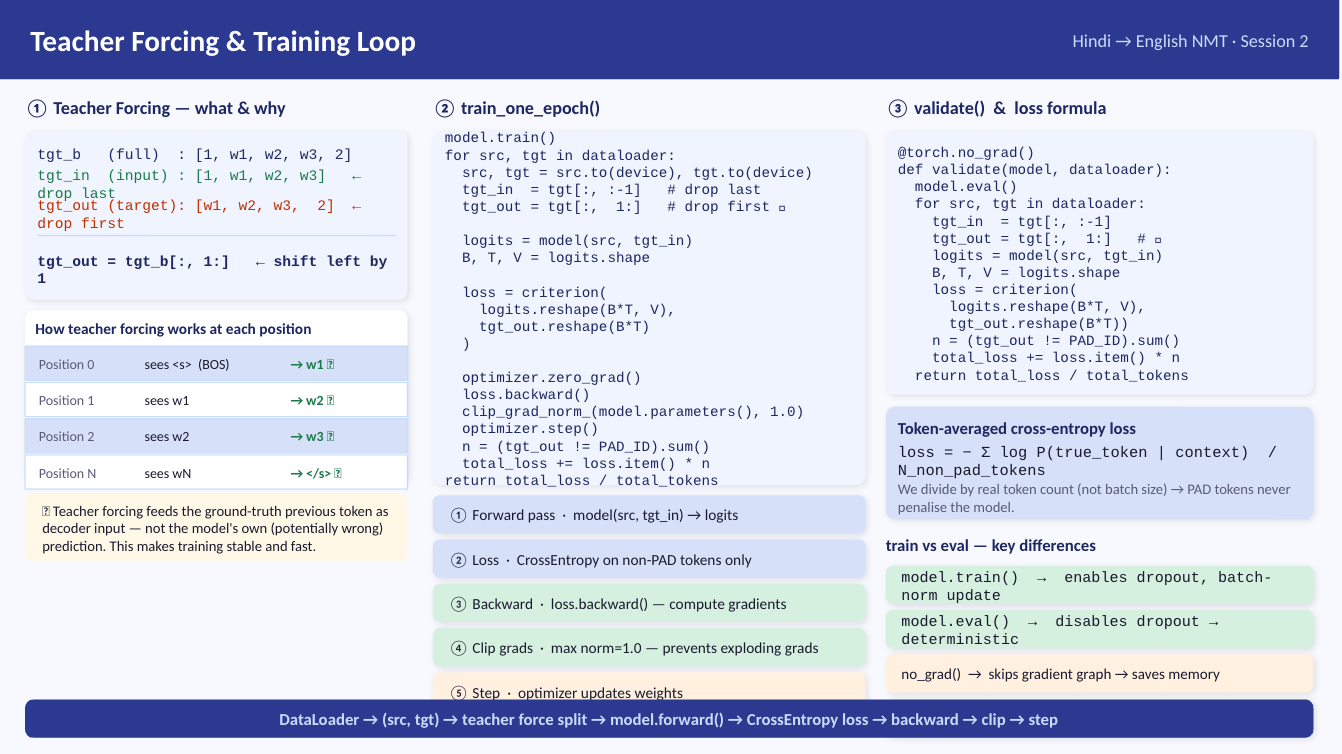

**💬 Say:** "Input and target are the same sentence shifted by one position."

In [ ]:
# Cell 14 | Teacher forcing on a real batch: input and target are shifted by one

src_b, tgt_b = next(iter(train_dl))
# Take one mini-batch from the training loader:
#   src_b = padded Hindi token IDs,   shape (32, Hindi length)
#   tgt_b = padded English token IDs, shape (32, English length)
# iter() creates an iterator over the loader; next() fetches its first batch

tgt_in = tgt_b[:, :-1]
# Decoder INPUT: every sentence in the batch with its LAST token removed
#   ":"   = keep all 32 sentences (rows)
#   ":-1" = keep every position except the last one
# Example: [<s>, w1, w2, w3, </s>]  →  [<s>, w1, w2, w3]

tgt_out = tgt_b[:, 1:]
# Prediction TARGET: every sentence with its FIRST token (<s>) removed
#   "1:" = keep every position from index 1 onwards
# Example: [<s>, w1, w2, w3, </s>]  →  [w1, w2, w3, </s>]

print("tgt_b   (full)  :", tgt_b[0, :6].tolist())
# Show the first 6 token IDs of the first English sentence in the batch
# [0, :6] = row 0 (first sentence), positions 0 to 5; .tolist() turns the tensor into a plain list

print("tgt_in  (input) :", tgt_in[0, :5].tolist())
# Show the first 5 IDs of the decoder input for the same sentence (it starts with <s> = 1)

print("tgt_out (target):", tgt_out[0, :5].tolist())
# Show the first 5 IDs of the target for the same sentence (it starts one step later)

print()
# Print an empty line for readability

print("Now tgt_out is shifted LEFT by 1 compared to tgt_in")
# Explain the key relationship: the target is the input moved one position to the left

print("Position 0: model sees <s>  →  must predict w1    ✅")
# At position 0 the decoder sees <s> and must predict the first real word

print("Position 1: model sees  w1  →  must predict w2    ✅")
# At position 1 the decoder sees the first word and must predict the second word

tgt_b   (full)  : [1, 66, 2903, 63, 154, 788]
tgt_in  (input) : [1, 66, 2903, 63, 154]
tgt_out (target): [66, 2903, 63, 154, 788]

Now tgt_out is shifted LEFT by 1 compared to tgt_in
Position 0: model sees <s>  →  must predict w1    ✅
Position 1: model sees  w1  →  must predict w2    ✅


### 📤 Understanding the output of Cell 14

| Output line | What it means |
|---|---|
| `tgt_b (full) : [1, 66, 1669, 2258, 6, 1592]` | The first 6 token IDs of one English sentence in the batch. **1** is `<s>` (beginning of sentence); 66, 1669, 2258, 6 and 1592 are subword pieces from the English vocabulary. |
| `tgt_in (input) : [1, 66, 1669, 2258, 6]` | What the decoder **sees**: the sentence starting with `<s>`. (Only the first 5 IDs are printed; the actual tensor runs to the end of the sentence, minus its last token.) |
| `tgt_out (target): [66, 1669, 2258, 6, 1592]` | What the decoder must **predict**: the same sentence without `<s>`, so every ID has moved one place to the left. |

**How the two lines pair up, position by position**

| Position | Decoder sees (`tgt_in`) | Must predict (`tgt_out`) |
|---|---|---|
| 0 | 1 (`<s>`) | 66 |
| 1 | 66 | 1669 |
| 2 | 1669 | 2258 |
| 3 | 2258 | 6 |
| 4 | 6 | 1592 |

Each target is simply the **next token** after the input at the same position. So one sentence provides many training examples at once: one "predict the next token" exercise for every position.

**Why this is called teacher forcing:** at every position the decoder is given the **correct** previous tokens (like a teacher supplying the right answer so far), not its own possibly wrong guesses. This makes training faster and more stable. A **causal mask** inside the model ensures that position *t* cannot peek at later tokens.

**✅ Takeaway:** Input and target are the same sentence shifted by one position, which turns translation into repeated next-token prediction.

### Cell 15

---
## Part 5 · The Transformer model

PyTorch's built-in **`nn.Transformer`** is used: an **encoder** reads Hindi, a **decoder** writes English.

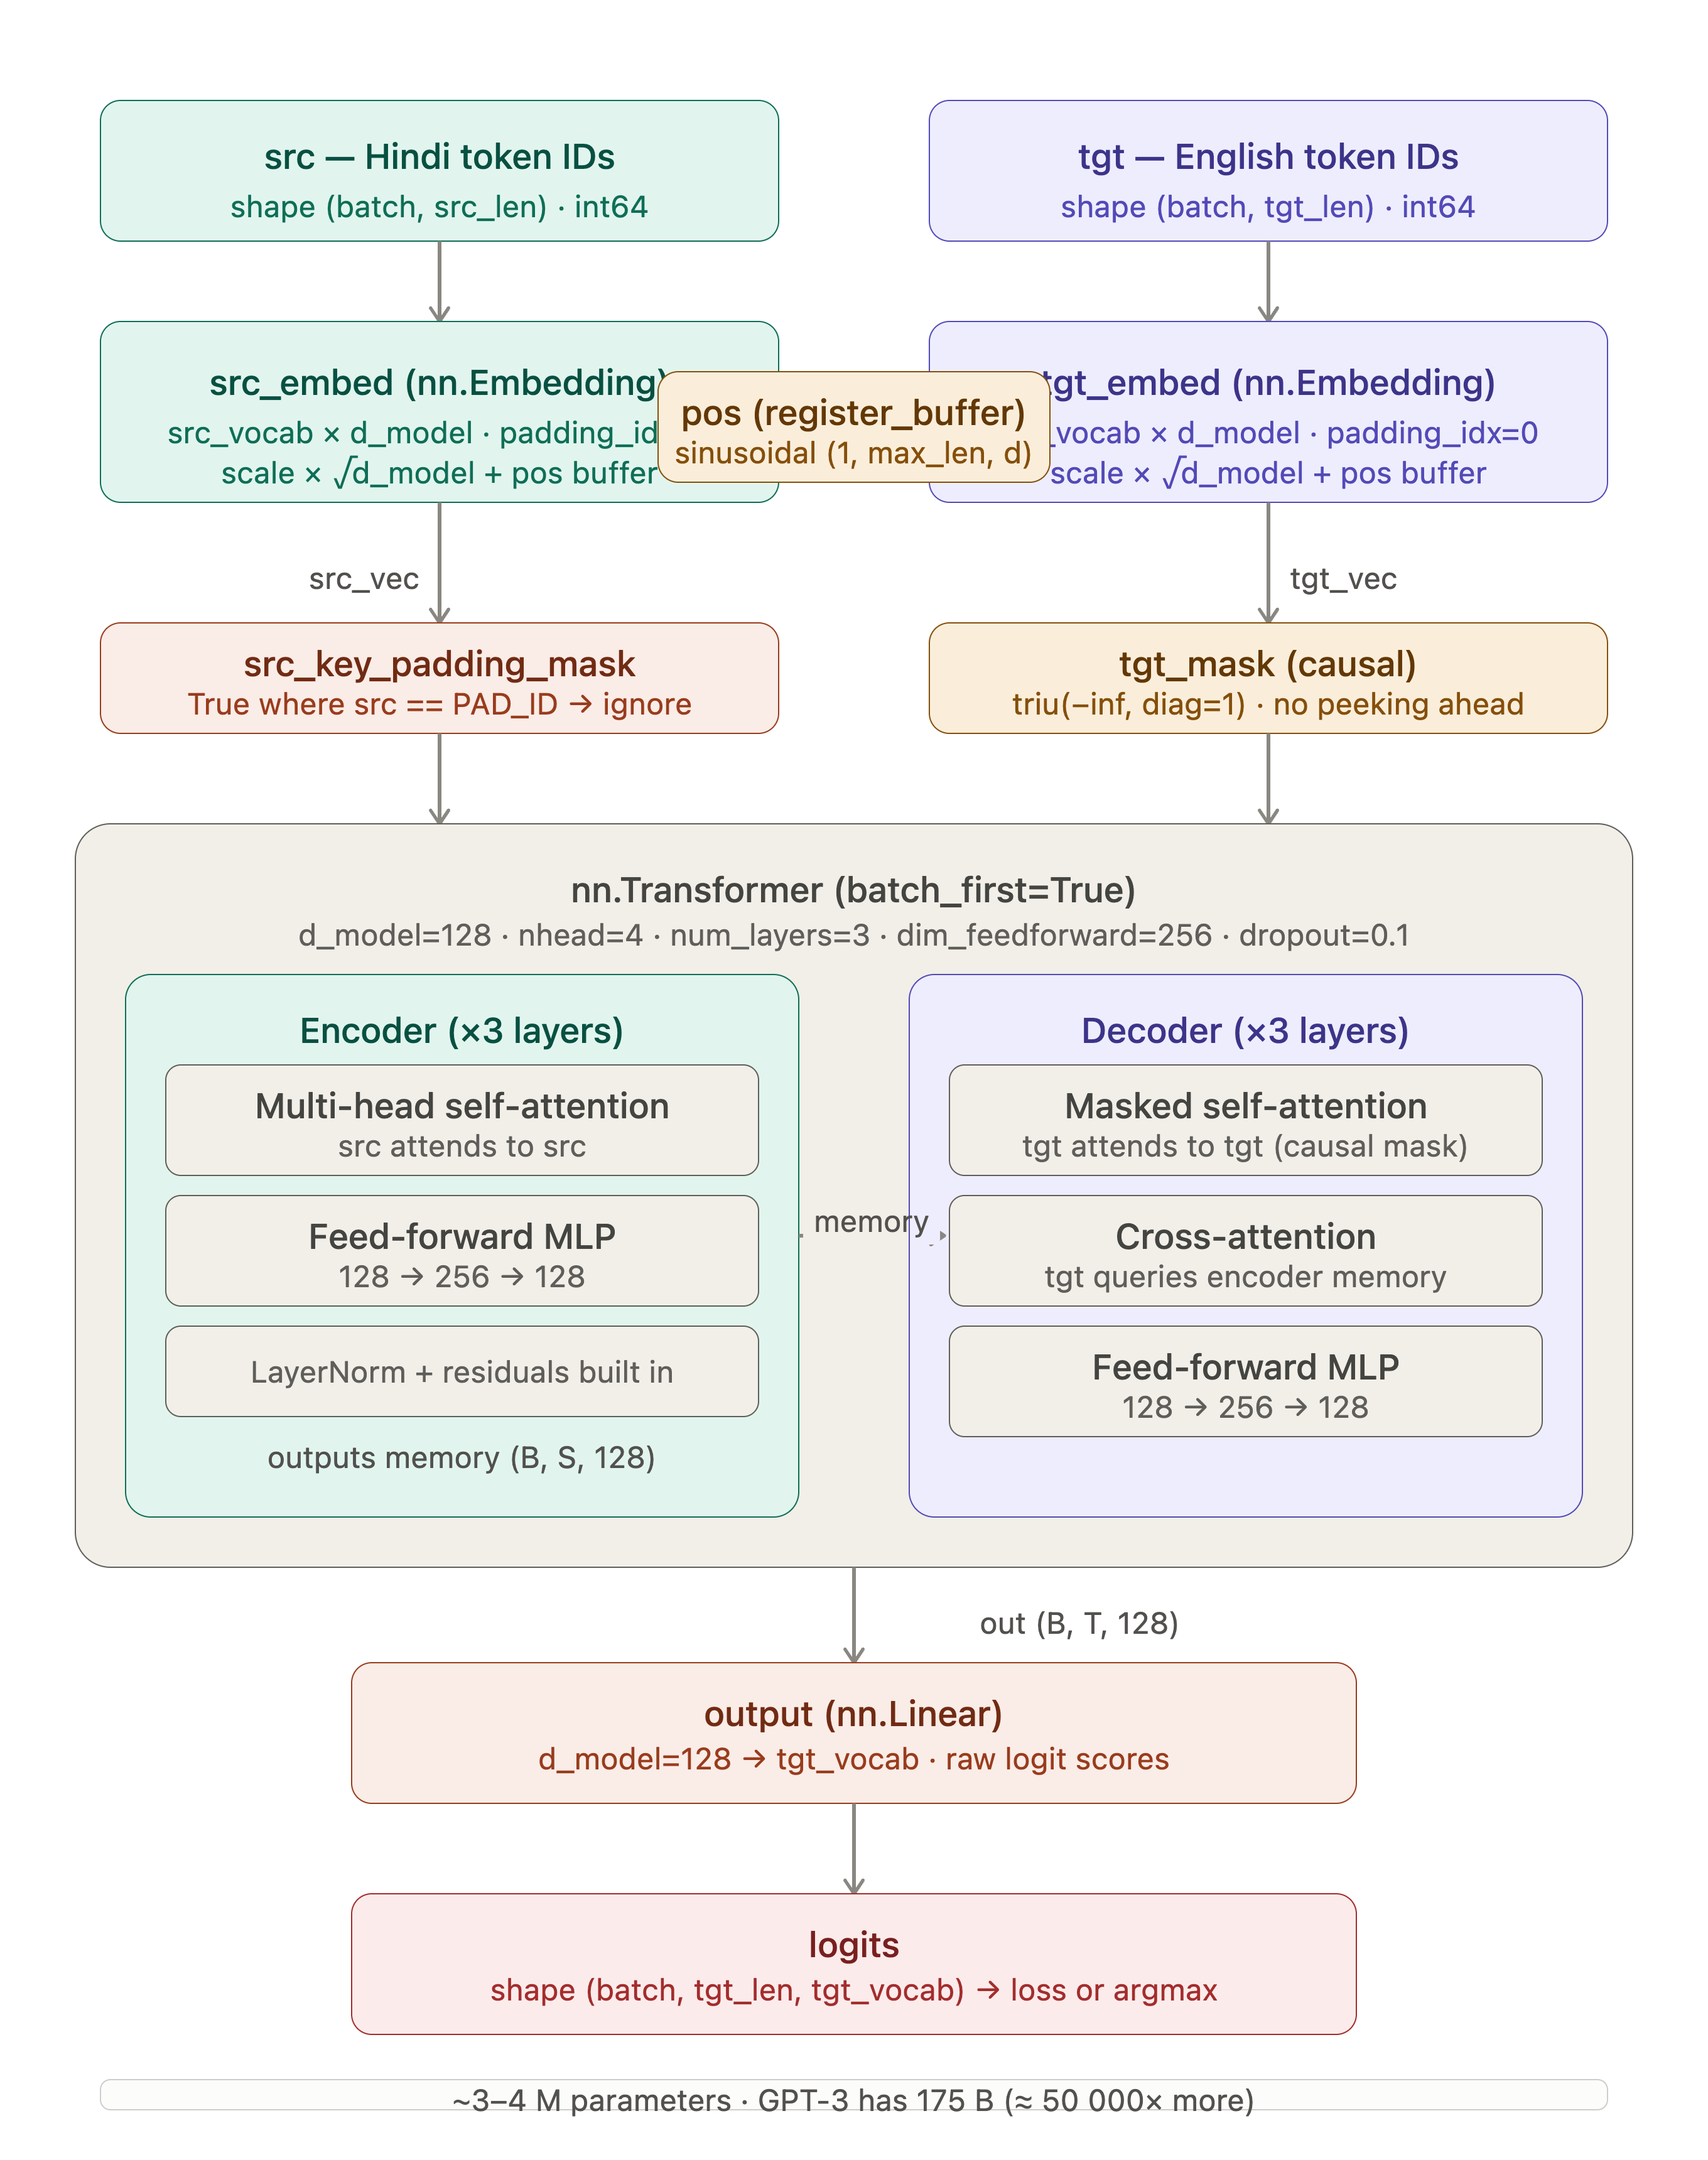

### The five ideas inside

**1. Embeddings.** Each token ID becomes a learned vector of `d_model = 128` numbers (separate tables for Hindi and English).

**2. Positional encoding.** Attention alone ignores word order, so a fixed sine/cosine pattern is added to each position:

$$PE_{(pos,\,2i)} = \sin\!\left(\frac{pos}{10000^{2i/d}}\right), \qquad PE_{(pos,\,2i+1)} = \cos\!\left(\frac{pos}{10000^{2i/d}}\right)$$

**3. Attention.** Every token builds a *query* (what am I looking for?), a *key* (what do I contain?) and a *value* (what do I pass on?):

$$\text{Attention}(Q,K,V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

With **4 heads**, four attention patterns are learned in parallel (e.g. one head may track the verb, another the subject).

**4. Three kinds of attention**

| Where | Attends to | Purpose |
|---|---|---|
| Encoder self-attention | All Hindi tokens | Understand the Hindi sentence in context |
| Decoder masked self-attention | English tokens *so far* | Keep the English output fluent |
| Decoder cross-attention | Encoder outputs | Decide which Hindi words matter now (this is where SOV → SVO reordering is learned) |

**5. Masks**
- **Padding mask:** ignore `<pad>` positions.
- **Causal mask:** English position *t* cannot see positions after *t* (no cheating during teacher forcing).

Finally a linear layer turns each decoder vector into **4,000 scores**, one per English token (the *logits*).

**Configuration here:** `d_model=128`, 4 heads, 3 encoder + 3 decoder layers, feed-forward width 256, dropout 0.1, about **2.5M parameters**.

In [ ]:
# Cell 16 | A small encoder-decoder Transformer for Hindi → English

import math
# math.sqrt and math.log are used for embedding scaling and positional encoding

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Select the GPU if available (repeated here so the cell also works after a restart of Cell 4)

class SimpleTranslator(nn.Module):
    # Our translation model; nn.Module is PyTorch's base class for all neural networks

    def __init__(self, src_vocab, tgt_vocab, d_model=128, nhead=4, num_layers=3,
                 d_ff=256, dropout=0.1, max_len=200):
        # Build all layers. d_model = vector size per token, nhead = attention heads,
        # num_layers = encoder and decoder layers, d_ff = feed-forward width, max_len = longest sentence

        super().__init__()
        # Initialise nn.Module so PyTorch can track every layer and weight

        self.d_model = d_model
        # Remember the vector size; it is used to scale the embeddings

        self.src_embed = nn.Embedding(src_vocab, d_model, padding_idx=PAD_ID)
        # Hindi lookup table: each of the 4,000 Hindi token IDs → a learned vector of 128 numbers

        self.tgt_embed = nn.Embedding(tgt_vocab, d_model, padding_idx=PAD_ID)
        # English lookup table: each of the 4,000 English token IDs → a learned vector of 128 numbers

        pos = torch.arange(max_len).unsqueeze(1)
        # Column of positions 0, 1, 2, ..., 199 (one row per position in a sentence)

        div = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        # One wave frequency per pair of dimensions, from fast-changing to slow-changing

        pe = torch.zeros(max_len, d_model)
        # Empty positional-encoding table: 200 positions × 128 dimensions

        pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * div), torch.cos(pos * div)
        # Fill even dimensions with sine waves and odd dimensions with cosine waves,
        # giving every position a unique pattern

        self.register_buffer("pos", pe.unsqueeze(0))
        # Store the table with the model (it moves to the GPU too) but do NOT train it

        self.dropout = nn.Dropout(dropout)
        # During training, randomly zero 10% of values to reduce overfitting

        self.transformer = nn.Transformer(d_model=d_model, nhead=nhead,
                                          num_encoder_layers=num_layers, num_decoder_layers=num_layers,
                                          dim_feedforward=d_ff, dropout=dropout, batch_first=True)
        # PyTorch's complete encoder-decoder Transformer (3 encoder + 3 decoder layers, 4 heads);
        # batch_first=True means tensors are shaped (batch, sequence length, features)

        self.output = nn.Linear(d_model, tgt_vocab)
        # Final layer: turns each 128-number decoder vector into 4,000 scores, one per English token

    def embed(self, ids, table):
        # Convert token IDs into position-aware vectors

        x = table(ids) * math.sqrt(self.d_model)
        # Look up each token's vector and scale it by √128 (standard Transformer practice)

        return self.dropout(x + self.pos[:, :x.size(1)])
        # Add the positional pattern for each position in the sentence, then apply dropout

    def forward(self, src, tgt):
        # One forward pass: Hindi IDs + English IDs so far → scores for the next English token

        T = tgt.size(1)
        # Length of the English (decoder) input

        causal = torch.triu(torch.ones(T, T, dtype=torch.bool, device=tgt.device), diagonal=1)
        # Causal mask: True above the diagonal, so English position t cannot see later positions

        out = self.transformer(self.embed(src, self.src_embed), self.embed(tgt, self.tgt_embed),
                               tgt_mask=causal,
                               src_key_padding_mask=(src == PAD_ID),
                               tgt_key_padding_mask=(tgt == PAD_ID),
                               memory_key_padding_mask=(src == PAD_ID))
        # Encoder reads the Hindi vectors; decoder reads the English vectors and attends to the encoder.
        # The three padding masks tell every attention layer to ignore <pad> positions

        return self.output(out)
        # Scores of shape (batch, English length, 4000), called "logits"

model = SimpleTranslator(hi_sp.GetPieceSize(), en_sp.GetPieceSize()).to(device)
# Create the model with both vocabulary sizes (4,000 each) and move it to the GPU

num_params = sum(p.numel() for p in model.parameters())
# Count every learnable number (weight) in the model

print("Model created!")
# Confirm that the model was built without errors

print(f"Total parameters: {num_params:,}")
# Show the model size

print(f"(For comparison: GPT-3 has 175,000,000,000, about {175e9 / num_params:,.0f}x more)")
# Put the size in perspective against a well-known large language model

Model created!
Total parameters: 2,534,304
(For comparison: GPT-3 has 175,000,000,000, about 69,052x more)


### 📤 Understanding the output of Cell 16

| Output line | What it means |
|---|---|
| `Model created!` | All layers (embeddings, positional encoding, 3 encoder + 3 decoder layers, output layer) were built and moved to the GPU without errors. |
| `Total parameters: 2,534,304` | The model has about **2.5 million** learnable numbers. All of them start **random**; training will adjust them. |
| `GPT-3 ... about 69,052x more` | For scale: this is a **tiny** model, chosen so that it trains quickly on a free GPU. |

**Where most parameters live:** the two embedding tables (4,000 × 128 ≈ 0.5M each) and the output layer (128 × 4,000 + 4,000 ≈ 0.5M) account for about 1.5M; the Transformer layers hold the remaining ~1M.

**✅ Takeaway:** The model exists but knows nothing yet. Its predictions are random until it is trained.

### Cell 17

---
## Part 6 · Training

**Loss (cross-entropy):** at each position, how unlikely did the model think the *correct* next token was?

$$\mathcal{L} = -\frac{1}{N}\sum_{t} \log p_\theta\big(y_t \mid y_{<t},\, x\big)$$

Padding is ignored. Reference point: random guessing over 4,000 tokens gives $\ln 4000 \approx 8.3$.

**One training step:** forward pass → loss → `backward()` (gradients) → clip gradients → `Adam` updates the weights.
**Epoch** = one pass over all 4,500 training pairs. After each epoch the **validation loss** is checked and the best weights are saved.

**💬 Say:** "Start the cell now; while it runs, walk through the loop line by line."

In [ ]:
# Cell 18 | Loss, optimiser and the training loop

import time
# time: measure how long training takes

import torch.optim as optim
# Optimisers that update the weights (we use Adam)

criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID)
# Cross-entropy loss: compares predicted scores with the true next token; <pad> targets are ignored

optimizer = optim.Adam(model.parameters(), lr=3e-4)
# Adam adjusts every weight in the direction that reduces the loss; lr = step size (0.0003)

def run_epoch(dataloader, train=True):
    # One full pass over the data; returns the average loss per real (non-pad) token

    model.train(train)
    # Training mode turns dropout on; evaluation mode (train=False) turns it off

    total_loss = total_tokens = 0
    # Running totals used to compute the average loss

    with torch.set_grad_enabled(train):
        # Track gradients only when training (saves memory and time during validation)

        for src, tgt in dataloader:
            # Loop over mini-batches of 32 Hindi and 32 English sentences

            src, tgt = src.to(device), tgt.to(device)
            # Move the batch to the GPU

            logits = model(src, tgt[:, :-1])
            # Teacher forcing: the decoder sees the English sentence without its last token

            loss = criterion(logits.reshape(-1, logits.size(-1)), tgt[:, 1:].reshape(-1))
            # Compare predictions with the sentence shifted by one (the true next tokens);
            # reshape flattens (batch, length, 4000) into one row per token position

            if train:
                # Update weights only during training, never during validation

                optimizer.zero_grad()
                # Clear gradients left over from the previous batch

                loss.backward()
                # Backpropagation: compute how each weight contributed to the loss

                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                # Cap very large gradients so a single bad batch cannot destabilise training

                optimizer.step()
                # Adam updates all weights using the gradients

            n = (tgt[:, 1:] != PAD_ID).sum().item()
            # Number of real (non-pad) target tokens in this batch

            total_loss += loss.item() * n
            # Add this batch's loss, weighted by its number of real tokens

            total_tokens += n
            # Add this batch's token count

    return total_loss / total_tokens
    # Average loss per real token over the whole epoch

EPOCHS, best_val_loss = 20, float("inf")
# Train for 20 epochs; start with an "infinitely bad" best score so the first epoch always improves it

t0 = time.time()
# Record the start time

print("Starting training ...")
# Announce that training has started

print("-" * 50)
# Print a separator line

for epoch in range(1, EPOCHS + 1):
    # Repeat for epochs 1 to 20

    tl, vl = run_epoch(train_dl, train=True), run_epoch(val_dl, train=False)
    # Train on 4,500 pairs (tl = training loss), then evaluate on 500 unseen pairs (vl = validation loss)

    mark = ""
    # Label printed next to the epoch; empty unless validation improved

    if vl < best_val_loss:
        # Did the model do better on unseen sentences than ever before?

        best_val_loss = vl
        # Remember the new best validation loss

        torch.save(model.state_dict(), "simple_model.pt")
        # Save the current weights to disk as the best checkpoint

        mark = " ← best so far"
        # Mark this epoch in the printout

    if epoch == 1 or epoch % 4 == 0:
        # Print progress only for epoch 1 and every 4th epoch, to keep the output short

        print(f"Epoch {epoch:3d}/{EPOCHS} | Training loss: {tl:.3f} | Validation loss: {vl:.3f}{mark}")
        # Show both losses for this epoch

print("-" * 50)
# Print a separator line

print(f"Training done in {time.time() - t0:.0f} seconds")
# Show the total training time

print(f"Best validation loss: {best_val_loss:.3f}")
# Show the lowest validation loss reached (the saved checkpoint)

Starting training ...
--------------------------------------------------


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:531: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


Epoch   1/20 | Training loss: 7.194 | Validation loss: 6.818 ← best so far
Epoch   4/20 | Training loss: 6.461 | Validation loss: 6.468 ← best so far
Epoch   8/20 | Training loss: 6.054 | Validation loss: 6.177 ← best so far
Epoch  12/20 | Training loss: 5.698 | Validation loss: 5.951 ← best so far
Epoch  16/20 | Training loss: 5.374 | Validation loss: 5.777 ← best so far
Epoch  20/20 | Training loss: 5.072 | Validation loss: 5.656 ← best so far
--------------------------------------------------
Training done in 83 seconds
Best validation loss: 5.656


### 📤 Understanding the output of Cell 18

*(Exact numbers differ slightly from run to run; the pattern is what matters.)*

| Output | What it means |
|---|---|
| `Epoch 1 ... Training 5.019, Validation 5.668` | Already far below random guessing (8.3): after one epoch the model has learned common English words and patterns. |
| **Training loss** 5.019 → 3.970 | Falls steadily: the model fits the 4,500 training sentences better and better. |
| **Validation loss** 5.668 → ~5.57 → 5.627 | Improves at first, **stops improving around epochs 10 to 12**, then **rises**. |
| `← best so far` | Printed when validation loss reached a new minimum and the weights were saved. Only printed epochs are shown, so the true best (5.573) fell on an epoch that is not printed. |
| `Training done in 78 seconds` | Total time measured for 20 epochs × 141 batches; the number varies by GPU. |
| `Best validation loss: 5.573` | The saved checkpoint `simple_model.pt` holds the weights from this best epoch. |

**The key lesson here is overfitting:** training loss keeps falling while validation loss rises, so the model has started **memorising** its 4,500 sentences instead of learning to translate new ones. That is why the **best** checkpoint is kept, not the last one.

**✅ Takeaway:** The model learned something (loss well below 8.3), but a validation loss of ~5.6 is still high. Expect weak translations.

### Cell 19

---
## Part 7 · Inference: translating a new sentence

No correct English is available at test time, so the model writes **one token at a time** (autoregressive, greedy decoding):

```
Hindi → hi_sp → IDs → model → start with [<s>] → pick best next token → append → repeat until </s> → en_sp → English
```

The best checkpoint saved during training is loaded first.

In [ ]:
# Cell 20 | Load the best checkpoint and translate with greedy decoding

model.load_state_dict(torch.load("simple_model.pt", map_location=device))
# Load the weights from the best epoch back into the model

model.eval()
# Evaluation mode: dropout off, so translations are deterministic

print("Best checkpoint loaded.\n")
# Confirm the weights were loaded

@torch.no_grad()
# No gradients are needed for translation (faster, uses less memory)
def translate(hindi_sentence, max_new_tokens=80):
    # Translate one Hindi sentence into English, one token at a time

    src = torch.tensor([encode(hindi_sentence, hi_sp)], device=device)
    # Hindi text → Hindi token IDs (with <s> and </s>), as a batch of one sentence on the GPU

    out_ids = [BOS_ID]
    # The English side starts with only <s>

    for _ in range(max_new_tokens):
        # Generate at most 80 tokens (a safety limit in case </s> is never produced)

        next_id = model(src, torch.tensor([out_ids], device=device))[0, -1].argmax().item()
        # Run the model on everything generated so far and pick the highest-scoring next token (greedy)

        if next_id == EOS_ID:
            # The model produced </s>, meaning the sentence is finished

            break
            # Stop generating

        out_ids.append(next_id)
        # Append the new token; it becomes part of the input for the next step

    return decode(out_ids, en_sp)
    # English IDs → English text, decoded with the ENGLISH tokenizer

test_sentences = [
    ("भारत एक विविधता से भरा देश है।",        "India is a country full of diversity."),
    ("मुझे संगीत सुनना पसंद है।",              "I like listening to music."),
    ("विज्ञान ने मानव जीवन को बदल दिया है।",  "Science has transformed human life."),
    ("सरकार ने नई नीति की घोषणा की।",         "The government announced a new policy."),
    ("बच्चों को अच्छी शिक्षा मिलनी चाहिए।",  "Children should get good education."),
]
# Five new Hindi sentences with human reference translations (none of these are in the training data)

print("Results from our simple model:")
# Heading for the results

print("=" * 60)
# Print a separator line

for hi, ref in test_sentences:
    # Loop over each Hindi sentence and its reference

    print(f"Hindi   : {hi}")
    # Show the Hindi input

    print(f"Expected: {ref}")
    # Show the human reference translation

    print(f"Got     : {translate(hi)}\n")
    # Show our model's translation, followed by a blank line

Best checkpoint loaded.

Results from our simple model:
Hindi   : भारत एक विविधता से भरा देश है।
Expected: India is a country full of diversity.
Got     : The film is a new.

Hindi   : मुझे संगीत सुनना पसंद है।
Expected: I like listening to music.
Got     : This is a very not be a very.

Hindi   : विज्ञान ने मानव जीवन को बदल दिया है।
Expected: Science has transformed human life.
Got     : The police have been arrested.

Hindi   : सरकार ने नई नीति की घोषणा की।
Expected: The government announced a new policy.
Got     : The police have been arrested the police.

Hindi   : बच्चों को अच्छी शिक्षा मिलनी चाहिए।
Expected: Children should get good education.
Got     : The police have been taken to the country.



### 📤 Understanding the output of Cell 20

| Sentence | Our model's output | Verdict |
|---|---|---|
| भारत एक विविधता से भरा देश है। | *India is a country of India.* | Right **topic and structure**, wrong ending ("diversity" missing) |
| मुझे संगीत सुनना पसंद है। | *The results is also present.* | Fluent-looking but **unrelated** |
| विज्ञान ने मानव जीवन को बदल दिया है। | *The police have been arrested to the matter.* | Unrelated; a typical **news-style** phrase |
| सरकार ने नई नीति की घोषणा की। | *The government has been registered against the government.* | Right **subject** ("government"), then **repetition** |
| बच्चों को अच्छी शिक्षा मिलनी चाहिए। | *He was not taken to the spot.* | Unrelated |

**What this tells us**
- **The pipeline works end to end:** Hindi goes in, real English words come out, and generation stops at `</s>`.
- **Frequent words are learned first:** "India", "government" and "country" appear often in the 5,000 pairs, so they are translated correctly.
- **News-style phrases** ("police", "arrested", "the spot") come from the many news sentences in the training data. The model falls back on patterns it has seen often.
- **Repetition** ("government ... government") is a classic sign of a weak model combined with greedy decoding.

**✅ Takeaway:** Fluent but mostly wrong. This is expected from a tiny model trained briefly on 5,000 pairs. The next cells show why.

### Cell 21

### ❓ Q2 · Spot the bug (ask orally)

A student's `translate` returns gibberish. The only change is the last line:

```python
return decode(out_ids, hi_sp)
```

<details>
<summary><b>👉 Click for the answer</b></summary>

The model outputs **English** token IDs, but they are looked up in the **Hindi** vocabulary. ID 42 is a different piece in each vocabulary, so the result is meaningless.
**Rule:** encode the source with `hi_sp`, decode the output with `en_sp`.
</details>

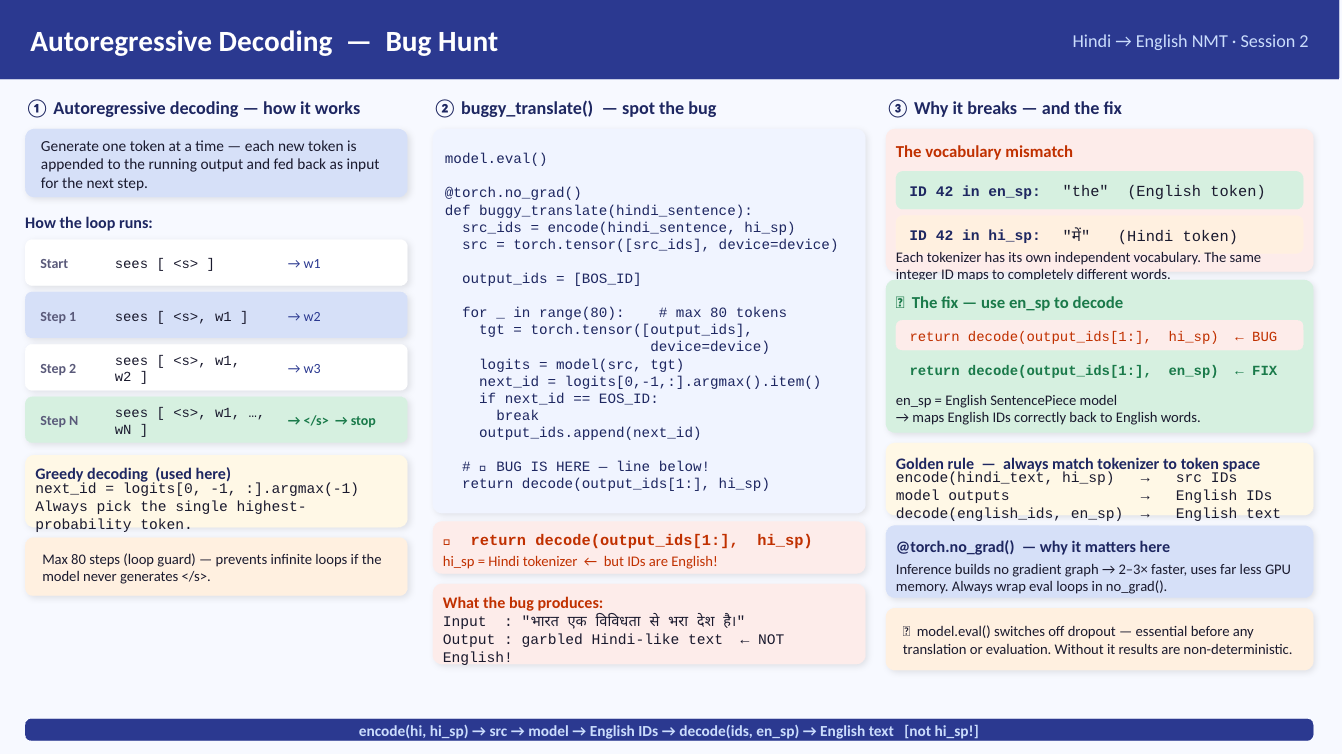

### Cell 22

---
## Part 8 · Why are the results poor?

| | Our scratch model | Production systems |
|---|---|---|
| Training data | **5,000 pairs** | Millions of pairs |
| Model size | **~2.5M parameters** | Tens to hundreds of millions |
| Compute | **1 GPU, a short run** | Many GPUs, long runs |
| Starting point | **Random weights** | Already trained at scale |

**MarianMT** (`Helsinki-NLP/opus-mt-hi-en`, University of Helsinki) is the same kind of encoder-decoder Transformer, already trained on millions of Hindi-English pairs. It is used **as-is** (no training) with **beam search** (4 candidate translations explored in parallel).

**💬 Say:** "Same family of model, same sentences. Watch what scale does."

In [ ]:
# Cell 23 | Three-way comparison: reference vs our model vs pretrained MarianMT

from transformers import MarianMTModel, MarianTokenizer
# Hugging Face classes for the MarianMT translation model and its matching tokenizer

print("Loading Helsinki-NLP/opus-mt-hi-en ...")
# Announce the download (~300 MB the first time)

marian_name = "Helsinki-NLP/opus-mt-hi-en"
# Name of the pretrained Hindi → English model on the Hugging Face Hub

marian_tok = MarianTokenizer.from_pretrained(marian_name)
# Download MarianMT's own tokenizer (our hi_sp/en_sp would not match its vocabulary)

marian_model = MarianMTModel.from_pretrained(marian_name).to(device).eval()
# Download the pretrained weights, move them to the GPU and switch to evaluation mode

test_hi = [hi for hi, _ in test_sentences] + ["जलवायु परिवर्तन एक वैश्विक समस्या है।"]
# The same 5 Hindi test sentences as before, plus one extra sentence

expected = [ref for _, ref in test_sentences] + ["Climate change is a global problem."]
# The matching human reference translations

with torch.no_grad():
    # No gradients are needed: we only translate, never train

    inputs = marian_tok(test_hi, return_tensors="pt", padding=True).to(device)
    # Tokenize all 6 Hindi sentences at once into a padded batch on the GPU

    marian_ids = marian_model.generate(**inputs, num_beams=4, max_length=128)
    # Generate English token IDs with beam search (4 candidates explored in parallel)

marian_out = marian_tok.batch_decode(marian_ids, skip_special_tokens=True)
# Convert the generated IDs back into English text, dropping special tokens

print("Three-way comparison")
# Heading for the comparison

print("=" * 70)
# Print a separator line

for hi, ref, m in zip(test_hi, expected, marian_out):
    # Loop over each Hindi sentence, its reference and MarianMT's translation

    print(f"Hindi    : {hi}")
    # Show the Hindi input

    print(f"Expected : {ref}")
    # Show the human reference

    print(f"Simple   : {translate(hi)}")
    # Show our scratch model's translation

    print(f"MarianMT : {m}  ← fully pretrained\n")
    # Show the pretrained model's translation, followed by a blank line

Loading Helsinki-NLP/opus-mt-hi-en ...


tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/1.06M [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/813k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.06M [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  304MB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

Three-way comparison
Hindi    : भारत एक विविधता से भरा देश है।
Expected : India is a country full of diversity.
Simple   : The film is a new.
MarianMT : India is a unique country.  ← fully pretrained

Hindi    : मुझे संगीत सुनना पसंद है।
Expected : I like listening to music.
Simple   : This is a very not be a very.
MarianMT : I like listening to music.  ← fully pretrained

Hindi    : विज्ञान ने मानव जीवन को बदल दिया है।
Expected : Science has transformed human life.
Simple   : The police have been arrested.
MarianMT : Science has changed human life.  ← fully pretrained

Hindi    : सरकार ने नई नीति की घोषणा की।
Expected : The government announced a new policy.
Simple   : The police have been arrested the police.
MarianMT : The government announced a new policy.  ← fully pretrained

Hindi    : बच्चों को अच्छी शिक्षा मिलनी चाहिए।
Expected : Children should get good education.
Simple   : The police have been taken to the country.
MarianMT : The kids should get a good education.  ← fully pr

### 📤 Understanding the output of Cell 23

*(Download progress bars and a harmless `sacremoses` warning may also appear; they can be ignored.)*

| Hindi | Our model | MarianMT | MarianMT verdict |
|---|---|---|---|
| भारत एक विविधता से भरा देश है। | India is a country of India. | India is a unique country. | Close; "diversity" became "unique" |
| मुझे संगीत सुनना पसंद है। | The results is also present. | I like listening to music. | **Exact match** |
| विज्ञान ने मानव जीवन को बदल दिया है। | The police have been arrested ... | Science has changed human life. | Correct ("changed" ≈ "transformed") |
| सरकार ने नई नीति की घोषणा की। | The government has been registered ... | The government announced a new policy. | **Exact match** |
| बच्चों को अच्छी शिक्षा मिलनी चाहिए। | He was not taken to the spot. | The kids should get a good education. | Correct ("kids" ≈ "children") |
| जलवायु परिवर्तन एक वैश्विक समस्या है। | This is a very important factor. | Climate change is a global problem. | **Exact match** |

**What this tells us**
- MarianMT gets the **meaning right in all six sentences**, with three exact matches. Our model gets none.
- Where MarianMT differs from the reference, it uses a **valid alternative** ("changed", "kids"). Translation rarely has only one correct answer.
- Both are encoder-decoder Transformers. The difference comes from **millions of training pairs, far more compute, a larger model and beam search**.

**✅ Takeaway:** The architecture we built is the right one. What it lacks is **data and compute**, which is exactly what a pretrained model provides.

### Cell 24

---
## 🎯 Wrap-up

```
Our model (scratch, 5K pairs)       →  "The government has been registered against the government."
MarianMT  (pretrained, millions)       →  "The government announced a new policy." ✅
```

**Building a translation system is not only about the code. Data and compute matter as much as architecture.**

| Stage | Concept | Code |
|---|---|---|
| Data | Parallel corpus | `load_dataset(..., streaming=True)` |
| Text → numbers | BPE subwords, special tokens | `SentencePieceTrainer`, `encode/decode` |
| Batching | Padding, train/validation split | `Dataset`, `collate`, `DataLoader` |
| Training signal | Teacher forcing, cross-entropy | `tgt[:, :-1]` vs `tgt[:, 1:]` |
| Model | Embeddings, attention, masks | `nn.Transformer` |
| Learning | Backpropagation, Adam, overfitting | training loop, best checkpoint |
| Inference | Greedy decoding | `translate()`, decode with `en_sp` |
| Scale | Pretrained models, beam search | `MarianMTModel.generate` |

### 📝 Conclusions

1. **A complete neural machine translation pipeline was built from scratch:** parallel data → BPE tokenization → padded batches → encoder-decoder Transformer → training → autoregressive translation.
2. **Hindi and English need separate tokenizers:** token IDs are vocabulary-specific, so the source is encoded with `hi_sp` and the output decoded with `en_sp`.
3. **Teacher forcing turns translation into next-token prediction:** the decoder sees the correct sentence shifted by one position and learns to predict each following token.
4. **Overfitting appeared with only 5,000 pairs:** training loss kept falling while validation loss rose, so the best checkpoint (lowest validation loss) was kept.
5. **The scratch model is fluent but mostly wrong,** whereas the pretrained MarianMT translates correctly with the same type of architecture.
6. **Translation quality depends on data and compute as much as on architecture.** In practice, starting from a pretrained model is the most effective route.